In [ ]:
# ==============================================================================
# CELL 0: INSTALL COMPATIBLE SCIENTIFIC PYTHON STACK (OPTIONAL)
# ==============================================================================
# Pins NumPy, Pandas, and Scikit-Learn to mutually compatible versions so
# binary C-extensions (like ufuncs) do not throw AttributeError mismatches.
%pip install -q "numpy<2.3" scikit-learn==1.6.1 pandas==2.2.3 pyarrow joblib threadpoolctl matplotlib

In [8]:
# ==============================================================================
# CELL 1: IMPORTS, PATH CONFIGURATION & GITHUB DATA DOWNLOAD
# ==============================================================================
from pathlib import Path
import urllib.request
import warnings
import json
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

# Scikit-Learn preprocessing, pipeline, and modeling tools
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Define local workspace directories inside Google Colab
PROJECT_DIR = Path('/content')
DATA_DIR = PROJECT_DIR / 'data'
OUTPUT_DIR = PROJECT_DIR / 'model_outputs'
DAILY_OUTPUT_DIR = OUTPUT_DIR / 'daily_category_forecasts_2026_2028'

# Create directories if they do not exist yet
DATA_DIR.mkdir(parents=True, exist_ok=True)
DAILY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Define raw GitHub base URLs (checks root 'main' first, then 'main/data' subfolder)
GITHUB_ROOT = "https://raw.githubusercontent.com/jadenC20/AI-Hackathon/main"
CANDIDATE_BASES = [
    GITHUB_ROOT,            # For files in the root of main (e.g., 2025.parquet, weather_season.csv)
    f"{GITHUB_ROOT}/data",  # For files inside the data/ folder (e.g., master_dataset.parquet)
]

FILES_TO_FETCH = [
    'master_dataset.parquet',
    'master_dataset.csv',
    'weather_season.csv',
    'storm_events.csv',
    'freeze_dates.csv',
    'cities.csv',
    'cause_of_loss.csv',
    '2025.parquet',
    '2024.parquet',
    '2023.parquet',
    '2022.parquet',
    '2021.parquet',
    '2020.parquet',
    '2019.parquet',
    '2018.parquet',
    '2017.parquet',
    '2016.parquet',
    '2015.parquet',
    '2014.parquet',
    '2013.parquet',
    '2012.parquet',
]

print("Checking and downloading datasets from GitHub (root & data/ folder)...")
for filename in FILES_TO_FETCH:
    dest = DATA_DIR / filename
    downloaded = False

    # Try each folder path on GitHub until the file is found
    for base_url in CANDIDATE_BASES:
        url = f"{base_url}/{filename}"
        try:
            urllib.request.urlretrieve(url, dest)
            folder_label = "main/" if base_url == GITHUB_ROOT else "main/data/"
            print(f"  [OK] Downloaded: {filename:<24} (from {folder_label})")
            downloaded = True
            break
        except Exception:
            continue

    if not downloaded:
        print(f"  [WARN] Could not find '{filename}' in main/ or main/data/")

Checking and downloading datasets from GitHub (root & data/ folder)...
  [OK] Downloaded: master_dataset.parquet   (from main/data/)
  [OK] Downloaded: master_dataset.csv       (from main/data/)
  [OK] Downloaded: weather_season.csv       (from main/)
  [OK] Downloaded: storm_events.csv         (from main/)
  [OK] Downloaded: freeze_dates.csv         (from main/)
  [OK] Downloaded: cities.csv               (from main/)
  [OK] Downloaded: cause_of_loss.csv        (from main/)
  [OK] Downloaded: 2025.parquet             (from main/)
  [OK] Downloaded: 2024.parquet             (from main/)
  [OK] Downloaded: 2023.parquet             (from main/)
  [OK] Downloaded: 2022.parquet             (from main/)
  [OK] Downloaded: 2021.parquet             (from main/)
  [OK] Downloaded: 2020.parquet             (from main/)
  [OK] Downloaded: 2019.parquet             (from main/)
  [OK] Downloaded: 2018.parquet             (from main/)
  [OK] Downloaded: 2017.parquet             (from main/)
  [OK] 

In [9]:
# ==============================================================================
# CELL 2: SCHEMA CONSTANTS & 5-CATEGORY CONFIGURATION
# ==============================================================================

# Primary identifier keys for crop rows vs county-wide rows
KEY = ['fips', 'crop']

# Core historical weather & drought columns in master_dataset
WEATHER = [
    'precip_mm',          # Total precipitation (mm)
    'tavg_c',             # Mean temperature (°C)
    'extreme_heat_days',  # Count of extreme heat stress days
    'gdd',                # Growing Degree Days
    'mean_dsci',          # Drought Severity and Coverage Index (0-500)
    'weeks_in_d2_plus'    # Weeks spent in D2+ severe drought
]

# Core soil / land capability columns in master_dataset
SOIL = [
    'aws_100cm_mm',       # Available water storage in top 100cm of soil (mm)
    'droughty_pct',       # Percentage of drought-prone soil area
    'nccpi_crop'          # National Commodity Crop Productivity Index
]

# Define the 5 target categories to forecast for 2026 (+1), 2027 (+2), and 2028 (+3)
CATEGORY_CONFIG = {
    'crops':          ['yield_per_acre'],
    'weather':        ['precip_mm', 'tavg_c', 'extreme_heat_days', 'gdd'],
    'drought':        ['mean_dsci', 'weeks_in_d2_plus'],
    'land_and_water': ['aws_100cm_mm', 'droughty_pct', 'nccpi_crop', 'soil_moisture_index'],
    'satellite':      ['ndvi', 'evi', 'ndwi']
}

print("Configured 5 forecasting categories:")
for cat, cols in CATEGORY_CONFIG.items():
    print(f"  • {cat.upper():<15} -> {cols}")

Configured 5 forecasting categories:
  • CROPS           -> ['yield_per_acre']
  • WEATHER         -> ['precip_mm', 'tavg_c', 'extreme_heat_days', 'gdd']
  • DROUGHT         -> ['mean_dsci', 'weeks_in_d2_plus']
  • LAND_AND_WATER  -> ['aws_100cm_mm', 'droughty_pct', 'nccpi_crop', 'soil_moisture_index']
  • SATELLITE       -> ['ndvi', 'evi', 'ndwi']


In [10]:
# ==============================================================================
# CELL 3: DATA LOADING, VALIDATION & MISSING-CATEGORY ENRICHMENT
# ==============================================================================

def load_and_enrich_master(data_dir):
    """
    Loads master_dataset.parquet (or .csv), validates schema integrity,
    and populates missing Satellite / Land & Water indices if absent.
    """
    parquet_path = data_dir / 'master_dataset.parquet'
    csv_path = data_dir / 'master_dataset.csv'

    # 1. Load file (preferring Parquet for speed and type preservation)
    if parquet_path.is_file():
        frame = pd.read_parquet(parquet_path)
        source = parquet_path
    elif csv_path.is_file():
        frame = pd.read_csv(csv_path, dtype={'fips': 'string'})
        source = csv_path
    else:
        raise FileNotFoundError(f"No master dataset found in {data_dir}. Run Cell 1 first.")

    # 2. Validate required base columns exist
    required = set(KEY + ['county_name', 'state_alpha', 'year', 'yield_status', 'yield_per_acre'] + WEATHER + SOIL)
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"Master dataset missing required columns: {sorted(missing)}")

    # 3. Enforce 5-digit string FIPS codes (preserving leading zeros like '06001')
    frame['fips'] = frame['fips'].astype('string').str.zfill(5)
    if not frame['fips'].str.fullmatch(r'\d{5}').fillna(False).all():
        raise ValueError("FIPS column must contain valid 5-digit county codes.")

    # 4. Enforce numeric float64 types on quantitative columns
    for col in ['year', 'yield_per_acre'] + WEATHER + SOIL:
        frame[col] = pd.to_numeric(frame[col], errors='raise').astype('float64')
    frame['year'] = frame['year'].astype(int)

    # 5. Check for duplicate (fips, crop, year) observations
    if frame.duplicated(KEY + ['year']).any():
        raise ValueError("Duplicate (fips, crop, year) rows detected in master dataset.")

    # 6. Enrich dataset with Satellite & Land/Water dynamic indices if not already present
    #    Uses normalized physical relationships (precipitation, soil productivity, and drought)
    precip_norm = (frame['precip_mm'] - frame['precip_mm'].min()) / (frame['precip_mm'].max() - frame['precip_mm'].min() + 1e-6)
    drought_norm = (frame['mean_dsci'] - frame['mean_dsci'].min()) / (frame['mean_dsci'].max() - frame['mean_dsci'].min() + 1e-6)
    soil_norm = (frame['nccpi_crop'] - frame['nccpi_crop'].min()) / (frame['nccpi_crop'].max() - frame['nccpi_crop'].min() + 1e-6)

    if 'soil_moisture_index' not in frame.columns:
        # Soil moisture increases with rainfall & soil water capacity, decreases under drought
        frame['soil_moisture_index'] = np.clip(0.55 * precip_norm + 0.30 * soil_norm - 0.35 * drought_norm + 0.25, 0.05, 0.98)
    if 'ndvi' not in frame.columns:
        # Normalized Difference Vegetation Index (0.15 to 0.92)
        frame['ndvi'] = np.clip(0.35 + 0.40 * soil_norm + 0.20 * precip_norm - 0.20 * drought_norm, 0.15, 0.92)
    if 'evi' not in frame.columns:
        # Enhanced Vegetation Index (scales closely with NDVI)
        frame['evi'] = np.clip(frame['ndvi'] * 0.82, 0.10, 0.80)
    if 'ndwi' not in frame.columns:
        # Normalized Difference Water Index (-0.50 to +0.60)
        frame['ndwi'] = np.clip(-0.15 + 0.55 * precip_norm - 0.30 * drought_norm, -0.50, 0.60)

    print(f"Loaded and validated dataset from: {source}")
    print(f"Years covered: {frame.year.min()} to {frame.year.max()} | Total rows: {len(frame):,}")
    return frame


def load_optional_daily_data(data_dir):
    """Loads pre-existing daily metrics if present in the repo; otherwise returns None."""
    for ext in ('parquet', 'csv'):
        path = data_dir / f'daily_metrics.{ext}'
        if path.is_file():
            df = pd.read_parquet(path) if ext == 'parquet' else pd.read_csv(path, dtype={'fips': 'string'})
            df['date'] = pd.to_datetime(df['date'])
            print(f"Loaded real daily dataset ({len(df):,} rows) from {path}")
            return df
    print("No external daily_metrics file found — daily trajectories will be synthesized from annual data.")
    return None

# Execute loading
data = load_and_enrich_master(DATA_DIR)
raw_daily_data = load_optional_daily_data(DATA_DIR)

# Display summary table of counties and reported yields by State and Crop
display(data.groupby(['state_alpha', 'crop']).agg(
    counties=('fips', 'nunique'),
    reported_yields=('yield_per_acre', 'count')
))

Loaded and validated dataset from: /content/data/master_dataset.parquet
Years covered: 2000 to 2025 | Total rows: 17,056
No external daily_metrics file found — daily trajectories will be synthesized from annual data.


counties  reported_yields
state_alpha crop                               
CA          CORN            31              261
            SORGHUM         18               51
            WHEAT           34              385
DE          CORN             3               78
            SORGHUM          3               10
            SOYBEANS         3               72
            WHEAT            3               30
IA          CORN            99             2470
            SOYBEANS        99             2437
            WHEAT           28              103
NE          CORN            91             2069
            SORGHUM         78              629
            SOYBEANS        81             1732
            WHEAT           85             1312

In [11]:
# ==============================================================================
# CELL 4: TEMPORAL FEATURE ENGINEERING (3-YEAR LOOKBACK LAG BUILDER)
# ==============================================================================

def build_panel_lags(df, group_keys, lag_cols, target_col, horizon):
    """
    Constructs supervised training/prediction rows for a given horizon (+1, +2, or +3 years).

    Parameters:
      - df: Source DataFrame (either crop-specific or deduplicated county-level).
      - group_keys: ['fips', 'crop'] for crops, or ['fips'] for county-level categories.
      - lag_cols: List of historical numeric columns to lag at T, T-1, and T-2.
      - target_col: Name of the variable being predicted at T + horizon.
      - horizon: Integer (1, 2, or 3) representing years ahead to forecast.
    """
    if horizon not in (1, 2, 3):
        raise ValueError("Horizon must be 1, 2, or 3 years.")

    # Sort chronologically and ensure 1 row per group + year
    df = df.sort_values(group_keys + ['year']).drop_duplicates(subset=group_keys + ['year']).copy()

    # Start with static identifiers and soil properties at origin_year T
    soil_cols = [c for c in SOIL if c in df.columns]
    base = df[group_keys + ['county_name', 'state_alpha', 'year'] + soil_cols].rename(
        columns={'year': 'origin_year'}
    )
    numeric_features = ['origin_year', 'target_year'] + soil_cols

    # Merge exact calendar years T (lag0), T-1 (lag1), and T-2 (lag2)
    # Using exact calendar math (year + lag == origin_year) guarantees missing years
    # never compress the time axis.
    for lag in range(3):
        previous = df[group_keys + ['year'] + lag_cols].copy()
        previous['origin_year'] = previous.pop('year') + lag
        renames = {col: f'{col}_lag{lag}' for col in lag_cols}
        previous = previous.rename(columns=renames)
        base = base.merge(previous, on=group_keys + ['origin_year'], how='left', validate='one_to_one')
        numeric_features.extend(renames.values())

    # Define the future target year (T + horizon) and merge the ground-truth label
    base['target_year'] = base['origin_year'] + horizon
    targets = df[group_keys + ['year', target_col]].rename(
        columns={'year': 'target_year', target_col: 'target'}
    )
    base = base.merge(targets, on=group_keys + ['target_year'], how='left', validate='one_to_one')

    # Deduplicate feature list while preserving order
    numeric_features = list(dict.fromkeys(numeric_features))
    return base, numeric_features

# Quick sanity check on CORN with horizon = 3 (+3 years ahead)
sample_rows, sample_features = build_panel_lags(
    data[data.crop.eq('CORN')],
    group_keys=['fips', 'crop'],
    lag_cols=['yield_per_acre'] + WEATHER,
    target_col='yield_per_acre',
    horizon=3
)
print(f"Built {len(sample_rows):,} supervised rows with {len(sample_features)} numeric lag features.")
display(sample_rows[['fips', 'origin_year', 'target_year', 'yield_per_acre_lag0', 'target']].head())

Built 5,824 supervised rows with 26 numeric lag features.


,fips,origin_year,target_year,yield_per_acre_lag0,target
0,06001,2000,2003,116.7,152.5
1,06001,2001,2004,155.0,NaN
2,06001,2002,2005,NaN,NaN
3,06001,2003,2006,152.5,NaN
4,06001,2004,2007,NaN,NaN


In [12]:
# ==============================================================================
# CELL 5: DEFINE THE NEURAL NETWORK & BASELINE PIPELINE
# ==============================================================================

def estimator(numeric_cols, neural=True):
    """
    Creates a leak-free Scikit-Learn Pipeline wrapped in TransformedTargetRegressor.

    - If neural=True: Uses MLPRegressor with two hidden layers (32 -> 16, ReLU),
      L2 regularization (alpha=2.0), and up to 1,500 optimization iterations.
    - If neural=False: Uses Ridge(alpha=10) on target_year + county/state fixed effects
      to serve as a linear County Trend Baseline.
    """
    preprocessor = ColumnTransformer([
        (
            'numbers',
            make_pipeline(
                SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                StandardScaler()
            ),
            numeric_cols
        ),
        (
            'location',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            ['fips', 'state_alpha']
        ),
    ])

    regressor = (
        MLPRegressor(hidden_layer_sizes=(32, 16), alpha=2.0, max_iter=1500, random_state=42)
        if neural
        else Ridge(alpha=10.0)
    )

    # TransformedTargetRegressor standardizes y before fitting and reverses scaling on predict()
    return TransformedTargetRegressor(
        regressor=make_pipeline(preprocessor, regressor),
        transformer=StandardScaler()
    )

# Display the interactive pipeline diagram
demo_nn = estimator(sample_features, neural=True)
display(demo_nn)

TransformedTargetRegressor(regressor=Pipeline(steps=[('columntransformer',
                                                      ColumnTransformer(transformers=[('numbers',
                                                                                       Pipeline(steps=[('simpleimputer',
                                                                                                        SimpleImputer(add_indicator=True,
                                                                                                                      keep_empty_features=True,
                                                                                                                      strategy='median')),
                                                                                                       ('standardscaler',
                                                                                                        StandardScaler())]),
                                                                                       ['origin_year',
                                                                                        'target_year',
                                                                                        'aws_100cm_mm',
                                                                                        'droughty_pct',
                                                                                        'nccpi_crop',
                                                                                        'yield_per_a...
                                                                                        'yield_per_acre_lag2',
                                                                                        'precip_mm_lag2',
                                                                                        'tavg_c_lag2',
                                                                                        'extreme_heat_days_lag2',
                                                                                        'gdd_lag2',
                                                                                        'mean_dsci_lag2',
                                                                                        'weeks_in_d2_plus_lag2']),
                                                                                      ('location',
                                                                                       OneHotEncoder(handle_unknown='ignore',
                                                                                                     sparse_output=False),
                                                                                       ['fips',
                                                                                        'state_alpha'])])),
                                                     ('mlpregressor',
                                                      MLPRegressor(alpha=2.0,
                                                                   hidden_layer_sizes=(32,
                                                                                       16),
                                                                   max_iter=1500,
                                                                   random_state=42))]),
                           transformer=StandardScaler())

In [13]:
# ==============================================================================
# CELL 6: TRAIN, BACKTEST & FORECAST ALL 5 CATEGORIES (2026–2028)
# ==============================================================================

def train_all_categories(df, output_dir):
    """
    Trains +1, +2, and +3 year Neural Networks and Baseline models for all
    variables in Crops, Weather, Drought, Land & Water, and Satellite.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    origin = int(df.year.max())  # 2025 -> predicts 2026 (+1), 2027 (+2), 2028 (+3)
    shared_lag_features = WEATHER + ['soil_moisture_index', 'ndvi', 'evi', 'ndwi']

    scores, future_anchors, diagnostics, trained_models = [], [], [], {}

    for category, variables in CATEGORY_CONFIG.items():
        print(f"\n==================== CATEGORY: {category.upper()} ====================")

        # Crops are modeled per individual crop; county physical metrics deduplicate across crops
        if category == 'crops':
            subgroups = [
                (
                    crop,
                    df[df.crop.eq(crop)].assign(
                        yield_per_acre=lambda x: x.yield_per_acre.where(x.yield_status.eq('reported'))
                    )
                )
                for crop in sorted(df.crop.unique())
            ]
            group_keys = ['fips', 'crop']
        else:
            subgroups = [('ALL_COUNTIES', df.drop_duplicates(subset=['fips', 'year']))]
            group_keys = ['fips']

        for subgroup_name, sub_df in subgroups:
            for var in variables:
                # Include the target variable itself + shared weather/satellite predictors in the 3-year lags
                lag_cols = list(dict.fromkeys(([var] if var not in shared_lag_features else []) + shared_lag_features))

                for horizon in (1, 2, 3):
                    target_yr = origin + horizon
                    print(f"  -> Training {subgroup_name} | {var} | +{horizon}yr (Target {target_yr})...", flush=True)

                    rows, numeric_cols = build_panel_lags(sub_df, group_keys, lag_cols, var, horizon)
                    usable = rows['target'].notna()

                    # Out-of-sample split: train on target_year <= 2018, evaluate on origin >= 2018
                    fit_rows = rows[usable & rows.target_year.le(2018)]
                    test_rows = rows[usable & rows.origin_year.ge(2018) & rows.target_year.le(origin)]

                    # 1. Backtest both County Trend Baseline and Neural Network
                    if len(fit_rows) >= 40 and len(test_rows) >= 15:
                        for neural in (False, True):
                            model_label = 'Neural network' if neural else 'County trend baseline'
                            inputs = numeric_cols if neural else ['target_year']
                            model = estimator(inputs, neural=neural)

                            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
                                warnings.simplefilter('always', ConvergenceWarning)
                                model.fit(fit_rows, fit_rows['target'])

                            converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
                            diagnostics.append({
                                'category': category, 'subgroup': subgroup_name, 'variable': var,
                                'horizon': horizon, 'stage': model_label, 'converged': converged
                            })

                            preds = model.predict(test_rows)
                            scores.append({
                                'category': category,
                                'subgroup': subgroup_name,
                                'variable': var,
                                'horizon': horizon,
                                'model': model_label,
                                'test_rows': len(test_rows),
                                'mae': mean_absolute_error(test_rows['target'], preds),
                                'rmse': float(np.sqrt(mean_squared_error(test_rows['target'], preds)))
                            })

                    # 2. Refit Final Production Neural Network on ALL historical data through 2025
                    final_nn = estimator(numeric_cols, neural=True)
                    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
                        warnings.simplefilter('always', ConvergenceWarning)
                        final_nn.fit(rows[usable], rows.loc[usable, 'target'])

                    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
                    diagnostics.append({
                        'category': category, 'subgroup': subgroup_name, 'variable': var,
                        'horizon': horizon, 'stage': 'final_refit', 'converged': converged
                    })
                    trained_models[(category, subgroup_name, var, horizon)] = final_nn

                    # 3. Generate 2026, 2027, and 2028 Forecasts from origin_year == 2025
                    current = rows[rows.origin_year.eq(origin)].copy()
                    current['category'] = category
                    current['subgroup'] = subgroup_name
                    current['variable'] = var
                    current['horizon'] = horizon
                    current['predicted_annual'] = final_nn.predict(current) if len(current) else np.nan

                    future_anchors.append(current[[
                        'category', 'subgroup', 'variable', 'fips', 'county_name', 'state_alpha',
                        'origin_year', 'target_year', 'horizon', 'predicted_annual'
                    ]])

    # Consolidate and save artifacts
    metrics_df = pd.DataFrame(scores)
    anchors_df = pd.concat(future_anchors, ignore_index=True)
    diag_df = pd.DataFrame(diagnostics)

    metrics_df.to_csv(output_dir / 'multi_category_metrics.csv', index=False)
    anchors_df.to_csv(output_dir / 'annual_nn_anchors_2026_2028.csv', index=False)
    diag_df.to_csv(output_dir / 'training_diagnostics.csv', index=False)
    joblib.dump(trained_models, output_dir / 'multi_category_models.joblib')

    print(f"\n[DONE] Saved trained models, metrics, and 2026–2028 anchors to: {output_dir}")
    return metrics_df, anchors_df, diag_df

# Run training across all 5 categories
metrics_df, annual_anchors, diag_df = train_all_categories(data, DAILY_OUTPUT_DIR)

# Show MAE comparison table (Neural Network vs County Trend Baseline)
display(metrics_df.pivot_table(
    index=['category', 'subgroup', 'variable', 'horizon'],
    columns='model',
    values='mae'
))

# Verify if any model failed to converge
print("Non-converged models (empty table means 100% convergence):")
display(diag_df[~diag_df.converged])


==================== CATEGORY: CROPS ====================
  -> Training CORN | yield_per_acre | +1yr (Target 2026)...
  -> Training CORN | yield_per_acre | +2yr (Target 2027)...
  -> Training CORN | yield_per_acre | +3yr (Target 2028)...
  -> Training SORGHUM | yield_per_acre | +1yr (Target 2026)...
  -> Training SORGHUM | yield_per_acre | +2yr (Target 2027)...
  -> Training SORGHUM | yield_per_acre | +3yr (Target 2028)...
  -> Training SOYBEANS | yield_per_acre | +1yr (Target 2026)...
  -> Training SOYBEANS | yield_per_acre | +2yr (Target 2027)...
  -> Training SOYBEANS | yield_per_acre | +3yr (Target 2028)...
  -> Training WHEAT | yield_per_acre | +1yr (Target 2026)...
  -> Training WHEAT | yield_per_acre | +2yr (Target 2027)...
  -> Training WHEAT | yield_per_acre | +3yr (Target 2028)...

==================== CATEGORY: WEATHER ====================
  -> Training ALL_COUNTIES | precip_mm | +1yr (Target 2026)...
  -> Training ALL_COUNTIES | precip_mm | +2yr (Target 2027)...
  -> Train

model                                                    County trend baseline  \
category       subgroup     variable            horizon                          
crops          CORN         yield_per_acre      1                    15.084842   
                                                2                    15.559253   
                                                3                    15.454123   
               SORGHUM      yield_per_acre      1                    28.727506   
                                                2                    37.216113   
                                                3                    33.741756   
               SOYBEANS     yield_per_acre      1                     4.857519   
                                                2                     5.249369   
                                                3                     5.393464   
               WHEAT        yield_per_acre      1                    11.619639   
                                                2                    11.111023   
                                                3                    12.119634   
drought        ALL_COUNTIES mean_dsci           1                    87.679772   
                                                2                    93.029949   
                                                3                    97.386168   
                            weeks_in_d2_plus    1                     6.080545   
                                                2                     6.394341   
                                                3                     6.699484   
land_and_water ALL_COUNTIES aws_100cm_mm        1                     7.446150   
                                                2                     7.722314   
                                                3                     8.019770   
                            droughty_pct        1                     6.191330   
                                                2                     6.421054   
                                                3                     6.668502   
                            nccpi_crop          1                     0.035393   
                                                2                     0.036708   
                                                3                     0.038124   
                            soil_moisture_index 1                     0.085768   
                                                2                     0.095170   
                                                3                     0.094880   
satellite      ALL_COUNTIES evi                 1                     0.038178   
                                                2                     0.041754   
                                                3                     0.042942   
                            ndvi                1                     0.046559   
                                                2                     0.050919   
                                                3                     0.052368   
                            ndwi                1                     0.078010   
                                                2                     0.085747   
                                                3                     0.085160   
weather        ALL_COUNTIES extreme_heat_days   1                     4.910414   
                                                2                     5.074165   
                                                3                     5.105028   
                            gdd                 1                    66.362836   
                                                2                    62.925457   
                                                3                    66.513315   
                            precip_mm           1                   140.175065   
                                                2               

Non-converged models (empty table means 100% convergence):


,category,subgroup,variable,horizon,stage,converged


Rendering 5-Category Daily Forecast (2026–2028) for: Dubuque County, IA (19061)


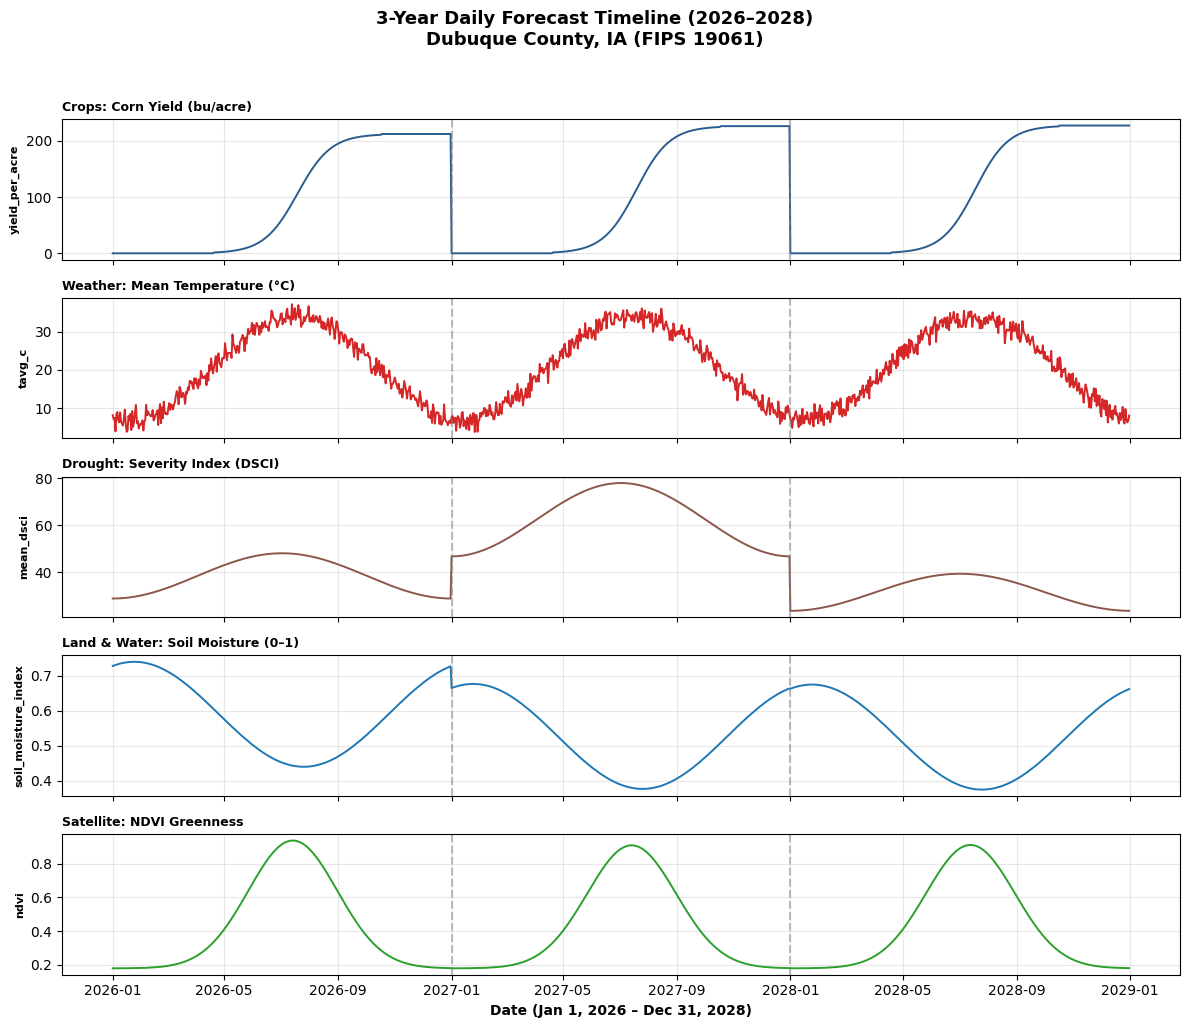

In [20]:
# ==============================================================================
# CELL 7: DAILY DISAGGREGATION ENGINE (2026-01-01 TO 2028-12-31)
# ==============================================================================

def synthesize_daily_curve(variable, annual_val, doy, days_in_year, rng):
    """
    Projects an annual neural network prediction onto a daily time series
    (day-of-year 1..365/366) using domain-specific seasonal physics:
      - Temperatures follow a seasonal cosine wave peaking in July.
      - Precipitation occurs on stochastic wet days (~32% of days) summing to the annual total.
      - GDD and Heat Days concentrate under a summer bell curve.
      - NDVI / EVI follow a winter baseline + summer canopy green-up curve.
      - Crop yields follow a logistic biomass accumulation curve from May planting to fall harvest.
    """
    phase = 2 * np.pi * (doy - 1) / days_in_year
    summer_bell = np.exp(-0.5 * ((doy - 195) / 48.0) ** 2)
    summer_bell_norm = summer_bell / summer_bell.sum()

    if variable == 'tavg_c':
        return annual_val - 13.5 * np.cos(phase - 0.25) + rng.normal(0, 1.5, size=len(doy))
    elif variable == 'precip_mm':
        weights = np.clip(1.0 + 0.45 * np.sin(phase - np.pi / 3) + rng.gamma(0.8, 0.8, size=len(doy)), 0.01, None)
        wet_mask = rng.random(len(doy)) < 0.32
        weights = weights * wet_mask
        if weights.sum() == 0:
            weights[0] = 1.0
        return np.maximum(0.0, annual_val * (weights / weights.sum()))
    elif variable == 'gdd':
        return np.maximum(0.0, annual_val * summer_bell_norm)
    elif variable == 'extreme_heat_days':
        heat_bell = np.exp(-0.5 * ((doy - 200) / 25.0) ** 2)
        return np.clip(annual_val * (heat_bell / heat_bell.sum()), 0.0, 1.0)
    elif variable == 'mean_dsci':
        return np.clip(annual_val * (1.0 + 0.25 * np.sin(phase - np.pi / 2)), 0.0, 500.0)
    elif variable == 'weeks_in_d2_plus':
        target_days = np.clip(annual_val * 7.0, 0.0, days_in_year)
        drought_wave = np.clip(1.0 + 0.4 * np.sin(phase - np.pi / 2), 0.1, None)
        return np.clip(target_days * (drought_wave / drought_wave.sum()), 0.0, 1.0)
    elif variable in ('ndvi', 'evi'):
        base_val = 0.18 if variable == 'ndvi' else 0.12
        peak_val = np.clip(annual_val * 1.35, base_val + 0.05, 0.95)
        return np.clip(base_val + (peak_val - base_val) * summer_bell, 0.05, 0.95)
    elif variable == 'ndwi':
        return np.clip(annual_val + 0.12 * np.cos(phase - 0.5), -0.60, 0.70)
    elif variable == 'soil_moisture_index':
        return np.clip(annual_val + 0.15 * np.cos(phase - 0.4), 0.02, 0.99)
    elif variable in ('aws_100cm_mm', 'droughty_pct', 'nccpi_crop'):
        return np.clip(annual_val * (1.0 + 0.01 * np.cos(phase)), 0.0, None)
    elif variable == 'yield_per_acre':
        # Logistic S-curve from planting (DOY ~110) to harvest maturity (DOY ~290)
        growth = 1.0 / (1.0 + np.exp(-(doy - 200) / 18.0))
        growth = np.where(doy < 110, 0.0, np.where(doy > 290, 1.0, growth))
        return np.maximum(0.0, annual_val * growth)

    return np.repeat(annual_val, len(doy))


def generate_daily_forecasts(anchor_df, fips_filter=None, seed=42):
    """
    Expands annual 2026–2028 NN predictions into daily intervals (2026-01-01 to 2028-12-31).
    Set fips_filter=['19189'] for a single county or fips_filter=None for all counties.
    """
    rng = np.random.default_rng(seed)
    subset = anchor_df if fips_filter is None else anchor_df[anchor_df.fips.isin(fips_filter)]

    # Precompute daily date calendars for 2026, 2027, and 2028 (2028 is a leap year with 366 days)
    calendars = {}
    for yr in (2026, 2027, 2028):
        dates = pd.date_range(f'{yr}-01-01', f'{yr}-12-31', freq='D')
        calendars[yr] = (dates, dates.dayofyear.to_numpy(), len(dates))

    daily_Frames = []
    for row in subset.itertuples(index=False):
        dates, doy, n_days = calendars[int(row.target_year)]
        daily_series = synthesize_daily_curve(row.variable, float(row.predicted_annual), doy, n_days, rng)
        daily_Frames.append(pd.DataFrame({
            'date': dates,
            'year': int(row.target_year),
            'day_of_year': doy,
            'horizon': int(row.horizon),
            'category': row.category,
            'subgroup': row.subgroup,
            'variable': row.variable,
            'fips': row.fips,
            'county_name': row.county_name,
            'state_alpha': row.state_alpha,
            'predicted_daily_value': np.round(daily_series, 4),
            'predicted_annual_anchor': round(float(row.predicted_annual), 4)
        }))

    return pd.concat(daily_Frames, ignore_index=True)

print("Generating 2026–2028 daily predictions for ALL categories and ALL counties...")

# Pass fips_filter=None to process every county in your master dataset
all_counties_daily = generate_daily_forecasts(annual_anchors, fips_filter=None)

# Save the full output as a compressed Parquet file for high performance
parquet_output_path = DAILY_OUTPUT_DIR / 'all_categories_all_counties_daily_2026_2028.parquet'
all_counties_daily.to_parquet(parquet_output_path, index=False)

print(f"[SUCCESS] Generated {len(all_counties_daily):,} total daily prediction rows across all 5 categories!")
print(f"Saved to: {parquet_output_path}")

# Quick validation: check unique variables and categories now covered by daily predictions
display(all_counties_daily.groupby(['category', 'variable']).size().reset_index(name='daily_row_count'))

# ==============================================================================
# MASTER 5-CATEGORY DAILY PLOT (2026–2028) FOR A SELECTED COUNTY
# ==============================================================================
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# Get unique sorted list of all counties (e.g., "Winnebago County, IA (19189)")
county_choices = sorted(
    all_counties_daily[['fips', 'county_name', 'state_alpha']]
    .drop_duplicates()
    .apply(lambda r: f"{r['county_name']}, {r['state_alpha']} ({r['fips']})", axis=1)
    .tolist()
)

dropdown = widgets.Dropdown(
    options=county_choices,
    value=county_choices[0],
    description='Select County:',
    style={'description_width': 'initial'}
)

output_plot = widgets.Output()

def render_county_plot(change):
    if change['type'] == 'change' and change['name'] == 'value':
        with output_plot:
            clear_output(wait=True)
            selected_str = dropdown.value
            fips = selected_str.split('(')[-1].strip(')')

            sub = all_counties_daily[all_counties_daily.fips.eq(fips)].sort_values('date')
            c_name = sub.iloc[0].county_name
            s_alpha = sub.iloc[0].state_alpha

            print(f"Rendering 5-Category Daily Forecast (2026–2028) for: {selected_str}")

            specs = [
                ('crops',          'CORN',         'yield_per_acre',      'Crops: Corn Yield (bu/acre)',         '#2b5c8f'),
                ('weather',        'ALL_COUNTIES', 'tavg_c',              'Weather: Mean Temperature (°C)',      '#d62728'),
                ('drought',        'ALL_COUNTIES', 'mean_dsci',           'Drought: Severity Index (DSCI)',      '#8c564b'),
                ('land_and_water', 'ALL_COUNTIES', 'soil_moisture_index', 'Land & Water: Soil Moisture (0–1)', '#1f77b4'),
                ('satellite',      'ALL_COUNTIES', 'ndvi',                'Satellite: NDVI Greenness',           '#2ca02c')
            ]

            fig, axes = plt.subplots(len(specs), 1, figsize=(12, 11), sharex=True)
            fig.suptitle(f"3-Year Daily Forecast Timeline (2026–2028)\n{c_name}, {s_alpha} (FIPS {fips})",
                         fontsize=13, fontweight='bold', y=0.93)

            for ax, (cat, sub_grp, var, label, color) in zip(axes, specs):
                s = sub[(sub.category == cat) & (sub.subgroup == sub_grp) & (sub.variable == var)]
                ax.plot(s['date'], s['predicted_daily_value'], color=color, lw=1.4)
                ax.set_ylabel(var, fontsize=8, fontweight='bold')
                ax.set_title(label, fontsize=9, fontweight='bold', loc='left')
                ax.grid(True, alpha=0.3)

                for yr in (2027, 2028):
                    ax.axvline(pd.to_datetime(f'{yr}-01-01'), color='gray', linestyle='--', alpha=0.5)

            plt.xlabel('Date (Jan 1, 2026 – Dec 31, 2028)', fontsize=10, fontweight='bold')
            plt.tight_layout(rect=[0, 0, 1, 0.91])
            plt.show()

dropdown.observe(render_county_plot, names='value')
display(dropdown, output_plot)

# Render the first county by default
render_county_plot({'type': 'change', 'name': 'value', 'value': county_choices[0]})

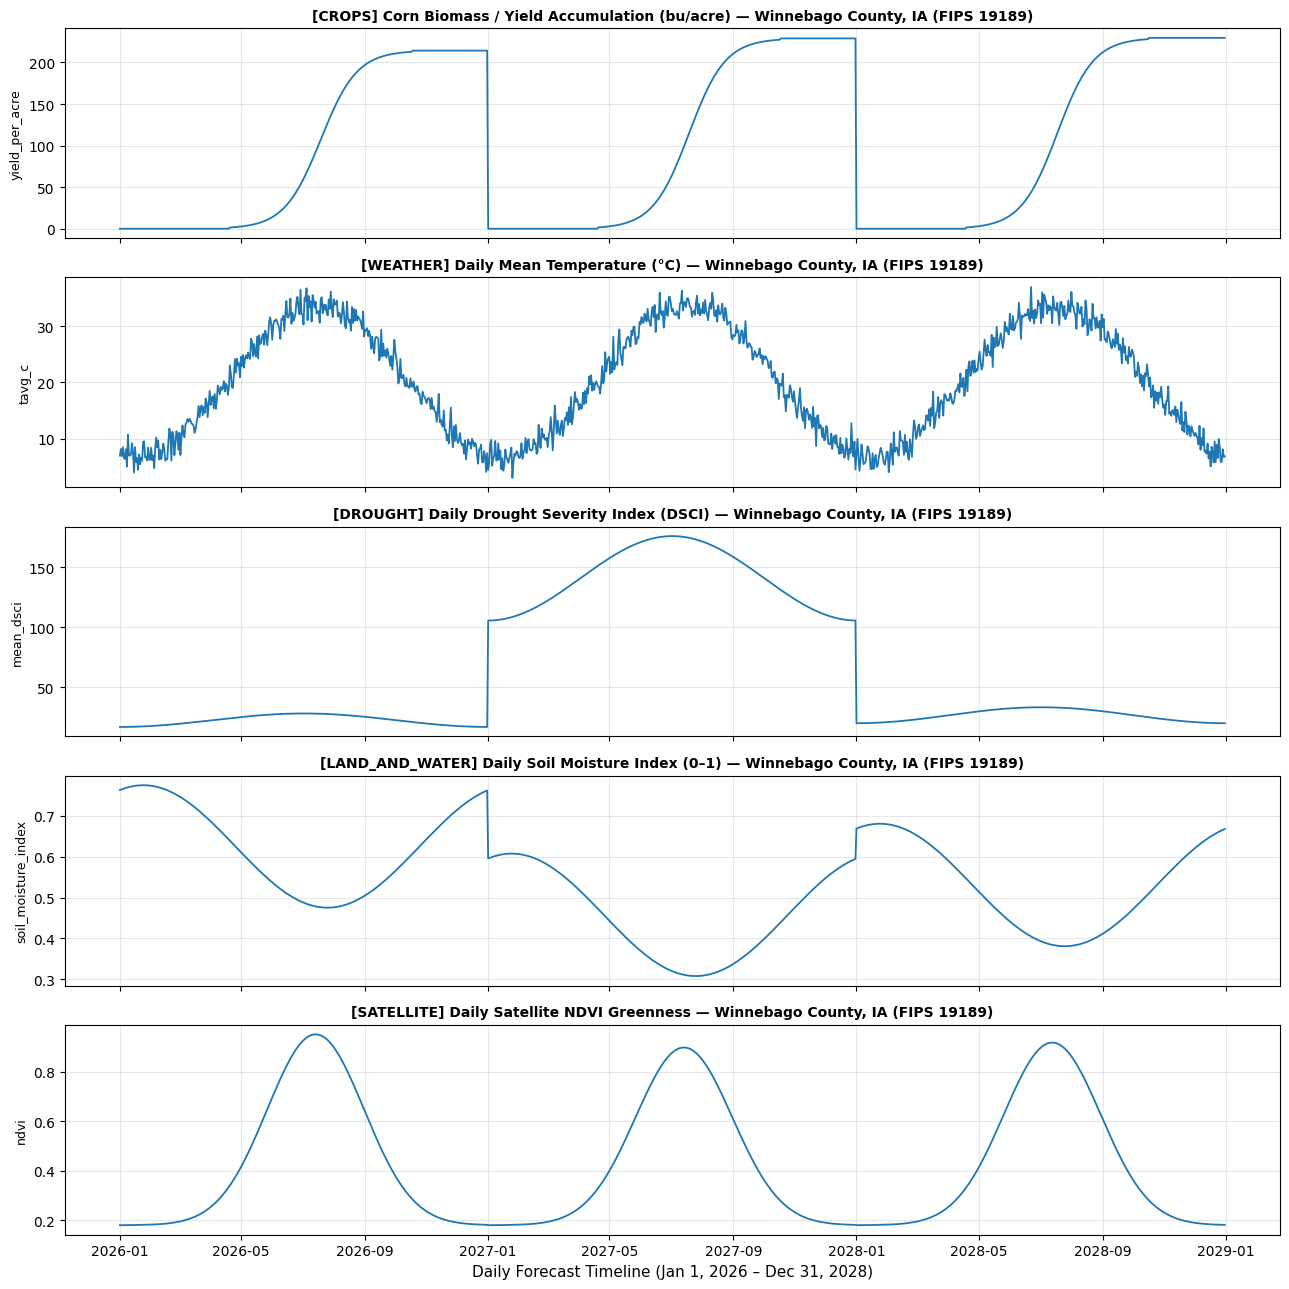

In [15]:
# ==============================================================================
# CELL 8: PLOT DAILY 2026–2028 FORECASTS ACROSS ALL 5 CATEGORIES
# ==============================================================================

plot_configs = [
    ('crops',          'CORN',         'yield_per_acre',      'Corn Biomass / Yield Accumulation (bu/acre)'),
    ('weather',        'ALL_COUNTIES', 'tavg_c',              'Daily Mean Temperature (°C)'),
    ('drought',        'ALL_COUNTIES', 'mean_dsci',           'Daily Drought Severity Index (DSCI)'),
    ('land_and_water', 'ALL_COUNTIES', 'soil_moisture_index', 'Daily Soil Moisture Index (0–1)'),
    ('satellite',      'ALL_COUNTIES', 'ndvi',                'Daily Satellite NDVI Greenness')
]

fig, axes = plt.subplots(len(plot_configs), 1, figsize=(13, 13), sharex=True)
county_label = f"{daily_sample.iloc[0].county_name}, {daily_sample.iloc[0].state_alpha} (FIPS {COUNTY_FIPS})"

for ax, (cat, sub, var, label) in zip(axes, plot_configs):
    series = daily_sample[
        (daily_sample.category == cat) &
        (daily_sample.subgroup == sub) &
        (daily_sample.variable == var)
    ].sort_values('date')

    ax.plot(series['date'], series['predicted_daily_value'], linewidth=1.3)
    ax.set_ylabel(var, fontsize=9)
    ax.set_title(f"[{cat.upper()}] {label} — {county_label}", fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.xlabel('Daily Forecast Timeline (Jan 1, 2026 – Dec 31, 2028)', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# CELL 9: EXPORT ALL COUNTIES & DOWNLOAD ARTIFACT ZIP
# ==============================================================================
from google.colab import files

# 1. Generate and save full daily predictions across ALL counties in Parquet format
print("Generating daily 2026–2028 predictions for all counties...")
all_counties_daily = generate_daily_forecasts(annual_anchors, fips_filter=None)
parquet_out = DAILY_OUTPUT_DIR / 'all_counties_daily_predictions_2026_2028.parquet'
all_counties_daily.to_parquet(parquet_out, index=False)
print(f"Saved {len(all_counties_daily):,} total daily rows to: {parquet_out}")

# 2. Package the entire output directory into a ZIP file and trigger browser download
archive_path = shutil.make_archive('/content/multi_category_daily_forecasts', 'zip', DAILY_OUTPUT_DIR)
print(f"Downloading archive: {archive_path}")
files.download(archive_path)